# Field of View (FOV) and Resolution

**Part:** G — Image characteristics · **Reading time:** ~60 min · **Pass 1 overview:** [Contrast and Image Quality](../pass1_big_picture/P1.4_Contrast_and_Image_Quality.ipynb) · **Refreshers you may want:** [Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb)

The image we create is fundamentally defined by the **field of view** (how large a region is imaged) and the **spatial resolution** (how fine a detail can be seen). Both are set entirely by *how we sample k-space*: the **spacing** of the samples fixes the FOV, the **extent** of the samples fixes the resolution. This chapter derives both rules from sampling theory, shows what goes wrong when they are violated (wrap-around aliasing, blurring and ringing), and translates them into the hardware quantities you actually set on a scanner: gradient amplitudes, dwell time and receiver bandwidth.

## Learning goals

1. Describe how images are formed
    * Describe what determines the image FOV and resolution
    * Derive $FOV=1/\Delta k$ and $\delta=1/(2k_{max})$ from the Fourier pairs comb ↔ comb and rect ↔ sinc
    * Recognize aliasing (wrap-around), blurring and Gibbs ringing, and explain their cause
1. Manipulate MRI sequence parameters to improve performance
    * Manipulate the gradients and k-space sampling to change the FOV and resolution
    * Compute $\Delta k$, $k_{max}$, gradient amplitudes, dwell time and readout duration for a desired FOV, matrix and bandwidth
    * Explain why readout oversampling is "free" while phase oversampling costs scan time

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $x$, $y$, $z$ | position; $x$ = readout (frequency-encode), $y$ = phase-encode, $z$ = slice direction | m | |
| $k$, $k_x$, $k_y$ | k-space coordinate (spatial frequency) | m⁻¹ (cycles/m) | $\vec k(t)=\bar\gamma\int_0^t\vec G\,d\tau$ |
| $\Delta k$, $\Delta k_x$, $\Delta k_y$ | spacing between neighbouring k-space samples | m⁻¹ | 2–5 m⁻¹ |
| $k_{max}$ | largest $\lvert k\rvert$ sampled | m⁻¹ | 100–1000 m⁻¹ |
| $W_k=2k_{max}$ | width of the sampled k-space region | m⁻¹ | $=N\Delta k$ |
| $FOV$, $FOV_x$, $FOV_y$ | field of view (period of the reconstructed image) | m | 0.2–0.5 m |
| $\delta$, $\delta_x$, $\delta_y$, $\delta_z$ | spatial resolution = pixel size (also written $\Delta x$); $\delta_z$ = slice thickness | m | 0.5–3 mm |
| $N$, $N_{read}$, $N_{PE}$ | number of samples (matrix size); readout samples; phase-encode steps | – | 128–512 |
| $p$ | k-space sample index, $p=-N/2,\dots,N/2-1$ | – | |
| $q$ | integer counting image replicas | – | |
| $m(x)$, $\hat m(x)$ | true object (transverse magnetization); reconstructed image | a.u. | complex |
| $M(k)$ | k-space data $=\mathcal F\{m\}$ (not the magnetization vector) | a.u. | |
| $\mathrm{rect}(u)$ | 1 for $\lvert u\rvert<1/2$, else 0 | – | |
| $\mathrm{sinc}(u)$ | $\sin(\pi u)/(\pi u)$ (normalized) | – | `mt.sinc` |
| $\mathrm{III}$, comb | train of Dirac deltas (sampling function) | – | |
| $\delta(\cdot)$ with an argument | Dirac delta — **not** the resolution $\delta$ | – | context tells |
| $*$ | convolution | | |
| $h(x)$, PSF | point spread function (image of a single point) | – | sinc for plain Cartesian sampling |
| FWHM | full width at half maximum of the PSF | m | $\approx1.21\,\delta$ |
| $\bar\gamma$ | gyromagnetic ratio $\gamma/2\pi$ | Hz/T | 42.58 MHz/T (¹H) |
| $G_{x,r}$ | readout gradient amplitude (figure: $G_{xr}$) | T/m | 1–40 mT/m |
| $G_{y,PE}$ | largest phase-encode gradient amplitude (figure: $G_{yp}$) | T/m | |
| $G_{yi}$ | phase-encode amplitude increment between steps | T/m | ~0.1 mT/m |
| $t_y$ | duration of the phase-encode lobe | s | 0.5–2 ms |
| $G_{max}$ | maximum gradient amplitude of the hardware | T/m | 40–80 mT/m |
| $\Delta t$ | dwell time between ADC samples (figure: $\Delta T_s$) | s | 2–20 µs |
| $BW_{read}=1/\Delta t$ | total receiver (readout) bandwidth (figure: RBW) | Hz | 30–500 kHz ("±BW/2") |
| $BW_{pixel}=BW_{read}/N_{read}$ | bandwidth per pixel | Hz/pixel | 100–1000 Hz |
| $T_{read}=N_{read}\Delta t$ | readout duration | s | 2–10 ms |
| $OS$ | readout oversampling factor | – | 2 |
| $t$, $TE$ | time; echo time (centre of the readout) | s | |
| $f$, $f_c$ | frequency (after demodulation); filter cutoff | Hz | |
| $H(f)$ | frequency response of the receiver's anti-aliasing filter | – | |
| $\Delta f_{cs}$ | fat–water chemical-shift frequency | Hz | ≈ −447 Hz at 3 T |
| $\Delta z$, $G_{z,SS}$, $BW_{rf}$ | slice thickness, slice-select gradient, RF bandwidth | m, T/m, Hz | see [Slice Selection](E2_Slice_Selection.ipynb) |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. What we actually measure: samples of $M(k)$ on a finite grid

From [K-space](F2_K-space.ipynb): the signal at time $t$ is the object's Fourier transform at $\vec k(t)$, $s(t)=M(\vec k(t))$. In a Cartesian scan we record $N$ samples per direction, spaced $\Delta k$ apart (1D for clarity):

$$ k_p = p\,\Delta k,\qquad p=-\tfrac N2,\dots,\tfrac N2-1 $$

In words: we know $M(k)$ only at $N$ equally spaced points, covering $-k_{max}\le k< k_{max}$ with $k_{max}=N\Delta k/2$.

Reconstruction (see [Image Reconstruction](F3_Image_Reconstruction.ipynb)) approximates the inverse Fourier integral by a sum over these samples:

$$ \hat m(x)=\sum_{p=-N/2}^{N/2-1} M(p\Delta k)\,e^{+i2\pi p\Delta k\,x}\,\Delta k $$

In words: the image is built from $N$ stripe patterns (complex exponentials) with frequencies $p\Delta k$, each weighted by the measured k-space value.

where $\hat m(x)$ = reconstructed image, $M(k)$ = k-space data, $\Delta k$ = sample spacing [m⁻¹], $x$ = position [m].

Two things differ from the ideal inverse FT: (1) **sampling** (only discrete $k$), (2) **truncation** (only $|k|\le k_{max}$). Each has a precise consequence.

### 1.1 The derivation in one line (comb ↔ comb, rect ↔ sinc)

Write the sampled, truncated k-space as the true $M(k)$ times a comb of deltas times a rectangular window:

$$ M_s(k) = M(k)\cdot\Delta k\sum_{p}\delta(k-p\Delta k)\cdot\mathrm{rect}\!\left(\frac{k}{W_k}\right) $$

In words: "true spectrum" × "keep only the grid points" × "keep only the central region of width $W_k=2k_{max}$".

Two standard Fourier pairs ([RM5 Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)):

* comb ↔ comb: $\ \Delta k\sum_p\delta(k-p\Delta k)\ \longleftrightarrow\ \sum_q\delta\!\left(x-\dfrac{q}{\Delta k}\right)$ — a comb of spacing $\Delta k$ transforms into a comb of spacing $1/\Delta k$,
* rect ↔ sinc: $\ \mathrm{rect}(k/W_k)\ \longleftrightarrow\ W_k\,\mathrm{sinc}(W_k x)$.

and the **convolution theorem** ([RM4](../refreshers/RM4_Fourier_Properties.ipynb)) — a product in one domain is a convolution ($*$) in the other — give

$$ \hat m(x)=\mathcal F^{-1}\{M_s\} = \Big[\sum_{q=-\infty}^{\infty} m\!\left(x-\frac{q}{\Delta k}\right)\Big] * W_k\,\mathrm{sinc}(W_k\,x) $$

In words: the reconstructed image is (i) the object **repeated** every $1/\Delta k$ metres, then (ii) **blurred** by a sinc whose main lobe has width $\sim1/W_k$.

where $q$ = integer labelling the copies, $W_k=2k_{max}=N\Delta k$. Hence the two rules:

$$ \boxed{FOV=\frac{1}{\Delta k}}\qquad\qquad \boxed{\delta=\frac{1}{W_k}=\frac{1}{2k_{max}}=\frac{FOV}{N}} $$

In words: the image repeats with period $FOV=1/\Delta k$; anything in the object outside a window of that size overlaps with its neighbours' copies (aliasing). The smallest distinguishable detail is about $1/(2k_{max})$, which equals the pixel size when $N$ samples are reconstructed into $N$ pixels.

<details><summary><b>📐 Derivation (optional): why sampling makes the image periodic, without distributions</b></summary>

Take a single point object at $x_0$: $m(x)=\delta(x-x_0)$, so $M(k)=e^{-i2\pi kx_0}$. At the sample points $k_p=p\Delta k$,

$$M(k_p)=e^{-i2\pi p\Delta k\,x_0}.$$

Now move the point by exactly $1/\Delta k$: $x_0\to x_0+1/\Delta k$. The samples become $e^{-i2\pi p\Delta k x_0}\,e^{-i2\pi p}=M(k_p)$, because $e^{-i2\pi p}=1$ for every integer $p$. **The data are identical**, so no reconstruction can tell $x_0$ from $x_0+FOV$: the image must be periodic with period $FOV=1/\Delta k$. Any object, being a sum of points, inherits this.

For the blur, insert the point into the sum:
$\hat m(x)=\Delta k\sum_{p=-N/2}^{N/2-1}e^{i2\pi p\Delta k(x-x_0)}$. This geometric series is the "Dirichlet kernel", which for large $N$ is $\approx W_k\,\mathrm{sinc}(W_k(x-x_0))$ within one FOV, with first zeros at $x-x_0=\pm1/W_k=\pm\delta$.

</details>

### 1.2 Seeing it: a "continuous" 1D object, sampled in k-space

We use an object made of rectangles, whose Fourier transform is known exactly (a rect of width $a$ centred at $c$ has $M(k)=a\,\mathrm{sinc}(ak)\,e^{-i2\pi kc}$), sample $M(k)$ on a grid, and evaluate the reconstruction sum on a fine $x$ grid **extending beyond the FOV** so that the periodic copies become visible. Units are real: FOV = 240 mm.

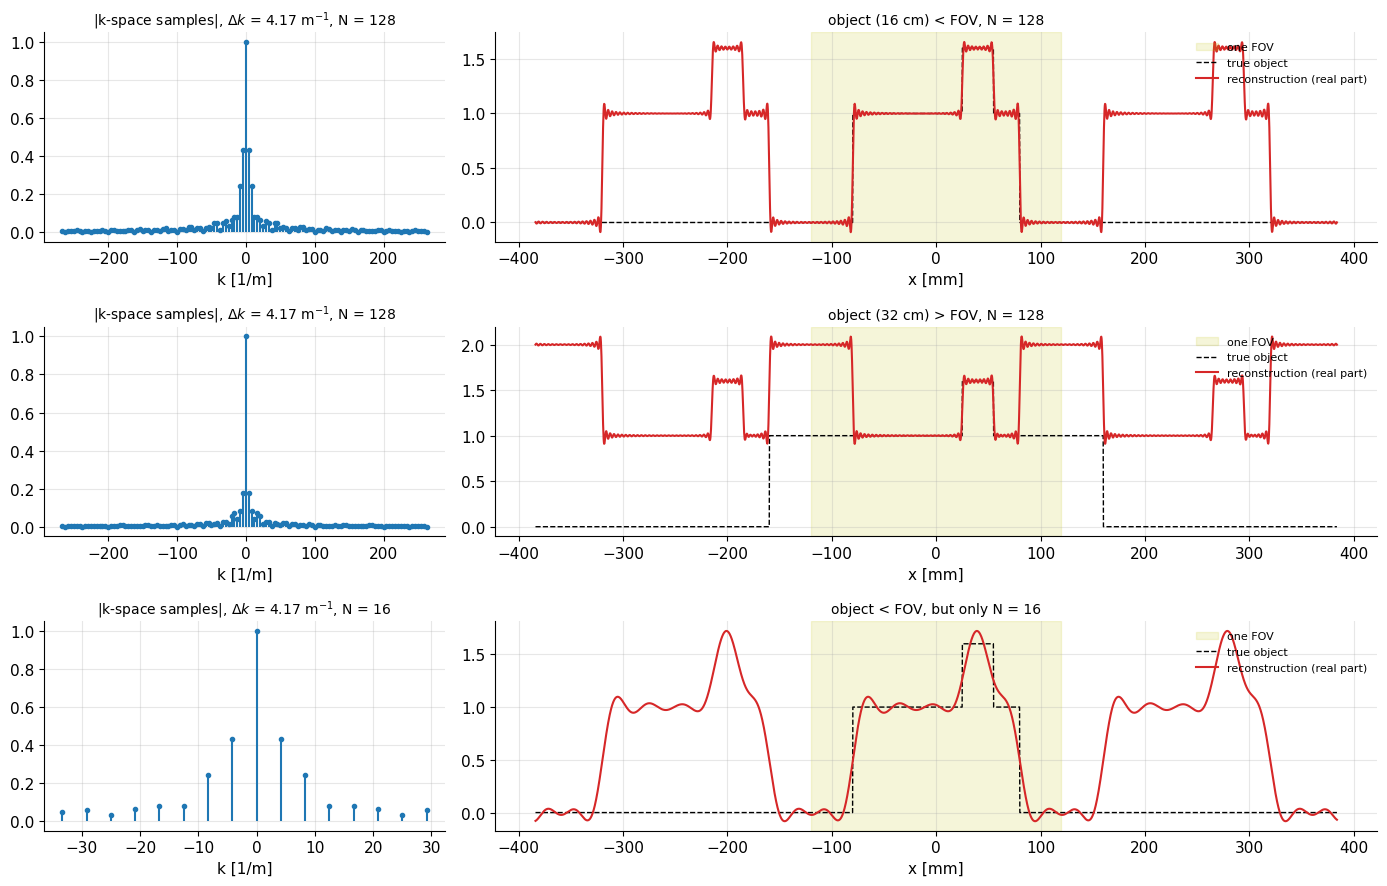

In [2]:
def rect_object(x, parts):
    """Object made of rectangles: parts = [(width [m], centre [m], amplitude), ...]."""
    return sum(a * mt.rect((x - c) / w) for w, c, a in parts)

def rect_object_ft(k, parts):
    """Exact Fourier transform of rect_object (kernel exp(-i 2 pi k x))."""
    return sum(a * w * mt.sinc(w * k) * np.exp(-1j * 2 * np.pi * k * c) for w, c, a in parts)

def recon_1d(parts, FOV, N, x):
    """Sample M(k) at k_p = p/FOV (p = -N/2..N/2-1) and evaluate the reconstruction sum at positions x."""
    dk = 1 / FOV
    k = np.arange(-N // 2, N // 2) * dk
    M = rect_object_ft(k, parts)
    return (np.exp(1j * 2 * np.pi * np.outer(x, k)) @ M) * dk, k, M

FOV = 0.24                                   # [m]
x = np.linspace(-1.6 * FOV, 1.6 * FOV, 3001) # positions [m], wider than the FOV
body = [(0.16, 0.0, 1.0), (0.03, 0.04, 0.6)]           # 16 cm "body" with a 3 cm brighter insert
wide = [(0.32, 0.0, 1.0), (0.03, 0.04, 0.6)]           # 32 cm object: larger than the FOV!
cases = [("object (16 cm) < FOV, N = 128", body, 128),
         ("object (32 cm) > FOV, N = 128", wide, 128),
         ("object < FOV, but only N = 16", body, 16)]

fig, axs = plt.subplots(3, 2, figsize=(14, 9), gridspec_kw={'width_ratios': [1, 2.2]})
for r, (title, parts, N) in enumerate(cases):
    mhat, k, M = recon_1d(parts, FOV, N, x)
    axs[r, 0].stem(k, np.abs(M) / np.abs(M).max(), basefmt=' ', markerfmt='C0.')
    axs[r, 0].set_title(f'|k-space samples|, $\\Delta k$ = {1/FOV:.2f} m$^{{-1}}$, N = {N}', fontsize=10)
    axs[r, 0].set_xlabel('k [1/m]')
    ax = axs[r, 1]
    ax.axvspan(-FOV / 2 * 1e3, FOV / 2 * 1e3, color='y', alpha=0.15, label='one FOV')
    ax.plot(x * 1e3, rect_object(x, parts), 'k--', lw=1, label='true object')
    ax.plot(x * 1e3, mhat.real, 'C3', lw=1.5, label='reconstruction (real part)')
    ax.set_title(title, fontsize=10); ax.set_xlabel('x [mm]'); ax.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()

Top: the reconstruction is a periodic train of copies spaced exactly 240 mm apart; inside the yellow FOV it equals the object (with slight ringing at edges). Middle: the 32 cm object is wider than the FOV, so neighbouring copies overlap — inside the FOV the object's own ends and the copies' ends add up: **aliasing**. Bottom: with only 16 samples $k_{max}$ is small, so edges are smeared over $\delta=240/16=15$ mm and the 3 cm insert is barely visible: **limited resolution**.

## 2. Field of View (FOV)

The FOV is determined by the sample spacing in k-space, with the simple relationship based on the sample spacing $\Delta k$:

$$ FOV = \frac{1}{\Delta k}$$

In words: the finer the k-space grid, the larger the imaged region. For example, $FOV_{x} = 1/\Delta k_x$ and $FOV_y=1/\Delta k_y$, independently per direction.

where $FOV$ [m], $\Delta k$ [m⁻¹]. Example: $\Delta k = 4.17\ \mathrm m^{-1}$ gives $FOV = 0.24$ m.

> **🧭 Intuition:** A sample at $k_p$ measures how well the object matches a stripe pattern of wavelength $1/k_p$. The *lowest* non-zero frequency $\Delta k$ is the longest stripe pattern we use, of wavelength $1/\Delta k$. All patterns repeat after that distance, so objects shifted by $1/\Delta k$ look the same in every measurement.

The next cell visualizes that statement: the stripe patterns of two positions $x_0$ and $x_0+FOV$ agree at every sampled $k$, though not between samples.

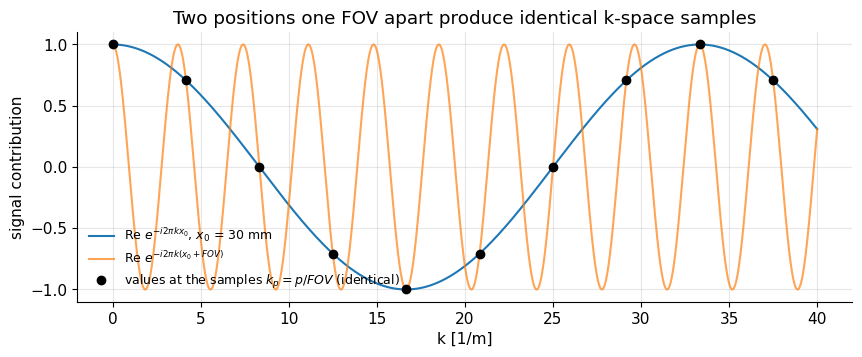

In [3]:
x0 = 0.03                                           # [m]
k_cont = np.linspace(0, 40, 2000)                   # continuous k axis [1/m]
k_samp = np.arange(0, 10) / FOV                     # sampled k values, Delta k = 1/FOV
plt.figure(figsize=(10, 3.5))
plt.plot(k_cont, np.cos(2 * np.pi * k_cont * x0), label=r'Re $e^{-i2\pi k x_0}$, $x_0$ = 30 mm')
plt.plot(k_cont, np.cos(2 * np.pi * k_cont * (x0 + FOV)), alpha=0.7, label=r'Re $e^{-i2\pi k (x_0+FOV)}$')
plt.plot(k_samp, np.cos(2 * np.pi * k_samp * x0), 'ko', label='values at the samples $k_p=p/FOV$ (identical)')
plt.xlabel('k [1/m]'); plt.ylabel('signal contribution'); plt.legend(loc='lower left', fontsize=9)
plt.title('Two positions one FOV apart produce identical k-space samples'); plt.show()

Between the samples the two curves differ strongly, but the scanner never looks there — so the two positions are indistinguishable.

### 2.1 The original demonstration: increasing $\Delta k$ shrinks the FOV

The original chapter builds a square object from its analytic k-space (product of two sincs) and then removes samples to increase $\Delta k$ by 2 and by 4. Zeroing every other sample while keeping the matrix is equivalent to sampling with $2\Delta k$ (the zeros contribute nothing to the sum), so the reconstruction now repeats every $FOV/2$: two copies per direction appear in the original FOV.

> **Correction to the original code:** it defined `sinc(x) = np.sinc(x/np.pi)`, i.e. the *unnormalized* $\sin(x)/x$, so the "square" was only $N_{rect}/\pi\approx5$ pixels wide instead of $N_{rect}=16$. Here we use the normalized `mt.sinc`, the k-space grid $p=-N/2..N/2-1$ and the centered `mt.ifft2c`. We also keep the samples that include $k=0$ when thinning.

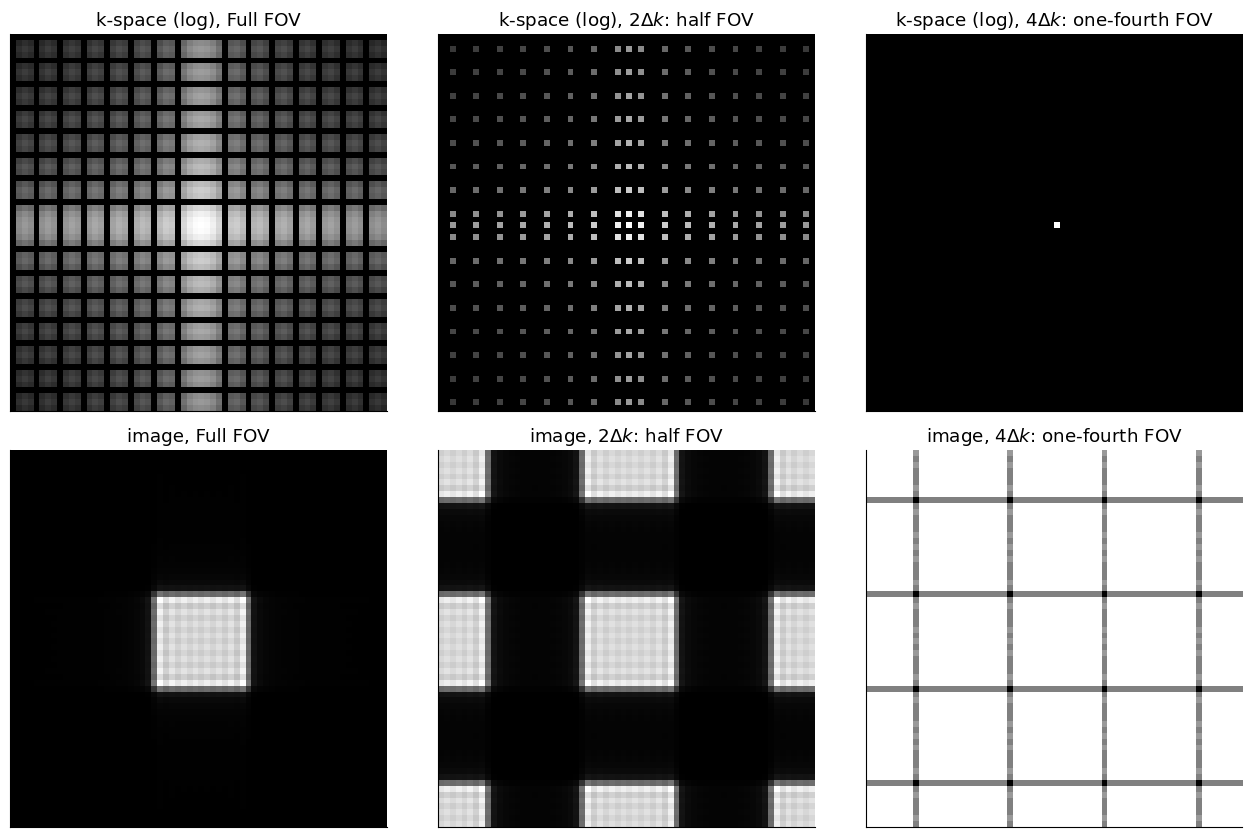

In [4]:
N = 64
kx = np.arange(-N // 2, N // 2) / N                  # k in cycles per pixel (Delta k = 1/N per pixel = 1/FOV)
N_rect = N // 4                                      # square of 16 x 16 pixels
kdata = np.outer(N_rect * mt.sinc(kx * N_rect), N_rect * mt.sinc(kx * N_rect))   # FT of rect is width*sinc

kdata2 = np.zeros_like(kdata); kdata2[::2, ::2] = kdata[::2, ::2]   # keep every 2nd sample (incl. k=0 at index 32)
kdata4 = np.zeros_like(kdata); kdata4[::4, ::4] = kdata[::4, ::4]   # keep every 4th sample

fig, axs = plt.subplots(2, 3, figsize=(13, 8.5))
for c, (kd, t) in enumerate([(kdata, 'Full FOV'), (kdata2, r'2$\Delta k$: half FOV'), (kdata4, r'4$\Delta k$: one-fourth FOV')]):
    axs[0, c].imshow(np.log10(np.abs(kd) + 1e-1), cmap='gray'); axs[0, c].set_title('k-space (log), ' + t)
    mt.show_image(mt.ifft2c(kd), ax=axs[1, c], title='image, ' + t)
    axs[0, c].set_xticks([]); axs[0, c].set_yticks([]); axs[0, c].grid(False)
plt.tight_layout(); plt.show()

With $2\Delta k$ the 64-pixel display contains $2\times2$ copies of the square (FOV halved in both directions), with $4\Delta k$ $4\times4$ copies; the 16-pixel square exactly fills the reduced FOV of 16 pixels, so copies touch. (Amplitude drops by 4 and 16 because fewer samples contribute.)

### 2.2 Aliasing (wrap-around) when the object is larger than the FOV

In practice we don't see "copies" — we only reconstruct one FOV. The copies of parts *outside* the FOV then land *inside* it on the opposite side: **wrap-around** or **fold-over**. Below, an analytic phantom (computed with `mt.disk_phantom_kspace`, so it is not artificially periodic) has a "body" and an "arm" that sticks out beyond the right edge of the FOV.

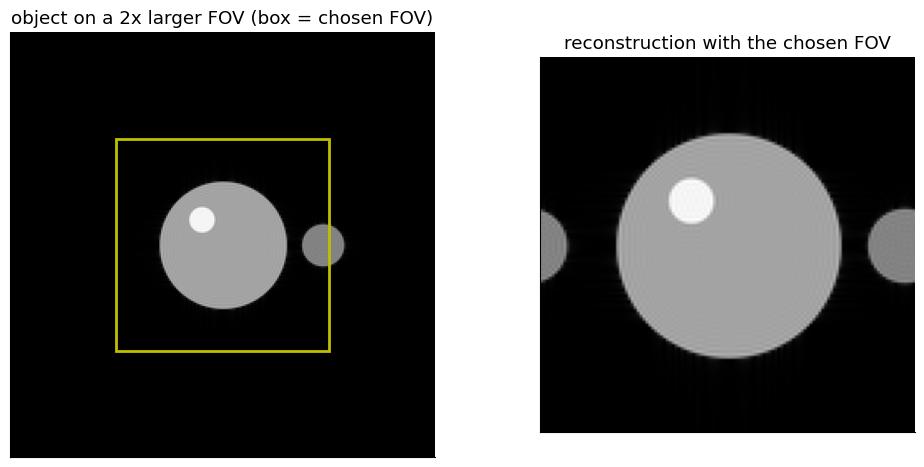

In [5]:
Nimg = 128
# phantom geometry in units of the *chosen* FOV (FOV spans -0.5..0.5): body r = 0.3, "arm" centred at 0.47 (outside beyond 0.5)
centers = ((0.0, 0.0), (0.47, 0.0), (-0.1, -0.12))
def phantom_k(N, scale):
    """Analytic k-space; scale = FOV_true / FOV_chosen (scale 2 = twice as large FOV, same pixel size if N doubled)."""
    K = np.zeros((N, N), complex)
    for (cx, cy), r, v in zip(centers, (0.3, 0.1, 0.06), (1.0, 0.8, 0.5)):
        K += mt.disk_phantom_kspace(N, centers=((cx / scale, cy / scale),), radius=r / scale, values=(v,))
    return K

img_big = mt.ifft2c(phantom_k(2 * Nimg, 2.0))     # FOV twice as large (and 2x samples): no wrap
img_fov = mt.ifft2c(phantom_k(Nimg, 1.0))         # chosen FOV: arm partly outside -> wraps

fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={'width_ratios': [2, 1]})
mt.show_image(img_big, ax=axs[0], title='object on a 2x larger FOV (box = chosen FOV)')
axs[0].add_patch(plt.Rectangle((Nimg / 2 - 0.5, Nimg / 2 - 0.5), Nimg, Nimg, fill=False, ec='y', lw=2))
mt.show_image(img_fov, ax=axs[1], title='reconstruction with the chosen FOV')
plt.tight_layout(); plt.show()

The part of the "arm" beyond the right edge reappears at the left edge of the image, overlapping nothing here, but in a real body it overlaps anatomy (the classic arm folding into the abdomen).

The same happens with real data: keeping every second phase-encode line of the brain data doubles $\Delta k_y$, halving $FOV_y$ — and the head no longer fits:

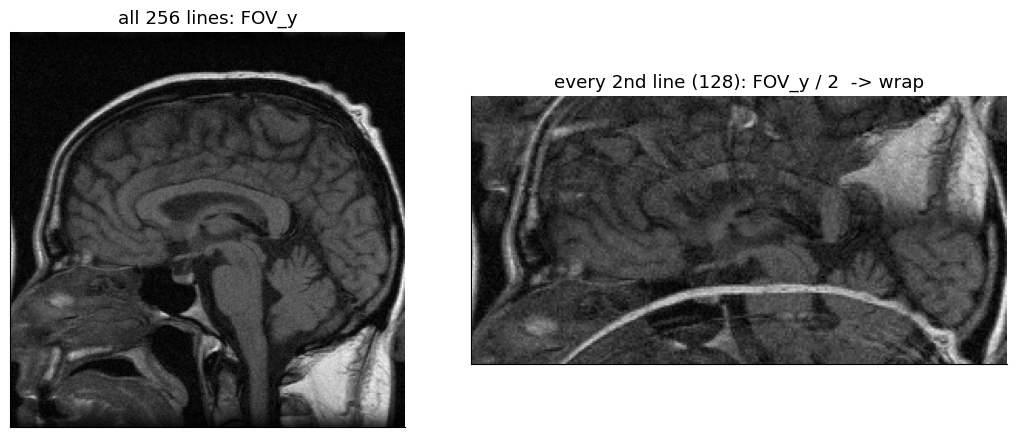

In [6]:
from scipy.io import loadmat
ksag = loadmat('../data/se_t1_sag_data.mat')['data']          # 256 x 256, rows = k_y
img_full = mt.ifft2c(ksag)
img_half = mt.ifft2c(ksag[::2, :])                              # 128 lines, Delta k_y doubled
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={'width_ratios': [1, 1]})
mt.show_image(img_full, ax=axs[0], title=f'all {ksag.shape[0]} lines: FOV_y')
mt.show_image(img_half, ax=axs[1], title=f'every 2nd line ({ksag[::2].shape[0]}): FOV_y / 2  -> wrap')
axs[1].set_aspect(1.0)   # pixel size unchanged: 128 rows x 256 columns
plt.tight_layout(); plt.show()

The top and bottom of the head wrap into the middle and overlap the brain. This is the price of naive undersampling; parallel imaging ([Accelerated Imaging Methods](H3_Accelerated_Imaging_Methods.ipynb)) undoes exactly this overlap using coil sensitivities.

> **🔧 Engineering reality:** Wrap-around is almost always a **phase-encode** problem. Remedies offered on scanners: enlarge $FOV_y$ (more PE lines → longer scan); "phase oversampling" / "no phase wrap" (acquire a larger FOV and discard the edges — costs time proportionally); choose the phase-encode direction along the body's shorter dimension; saturation bands that null signal outside the FOV; or rely on the limited sensitivity range of local receive coils. In the **readout** direction, the receiver's anti-aliasing filter prevents wrap (Section 5).

## 3. Spatial resolution

The spatial resolution is determined by the maximum sample extent in k-space, with the simple relationship based on the maximum k-space sample location $k_{max}$:

$$ \delta = \frac{1}{2 k_{max}}$$

In words: to see details of size $\delta$ you must measure stripe patterns down to a wavelength of $2\delta$ — i.e. spatial frequencies up to $k_{max}=1/(2\delta)$ (one bright and one dark pixel per stripe period, the Nyquist limit).

where $\delta$ = resolution / pixel size [m], $k_{max}$ [m⁻¹]. For example, $\delta_x = 1/(2 k_{x,max})$. Example: $k_{max}=533\ \mathrm m^{-1}\Rightarrow\delta=0.94$ mm.

For symmetric sampling in k-space, this can also be written using the width of the k-space sampling, $W_k = 2 k_{max}$:

$$ \delta = \frac{1}{W_k}$$

In words: the wider the sampled k-space region, the finer the detail. Combining with $FOV=1/\Delta k$ and $W_k=N\Delta k$ gives $\delta=FOV/N$: pixel size = FOV / matrix size.

### 3.1 The original demonstration: two points, shrinking $k_{max}$

The original builds two point objects on the centre row and then zeroes the outer k-space to halve and quarter $k_{max}$.

> **Correction:** the original comment said the points are "separated by 1 pixel". With $M(k)=e^{i\pi k\cdot4}+e^{-i\pi k\cdot4}=e^{-i2\pi k(-2)}+e^{-i2\pi k(+2)}$ ($k$ in cycles/pixel) the points sit at $x=\pm2$ pixels, i.e. **4 pixels apart**.

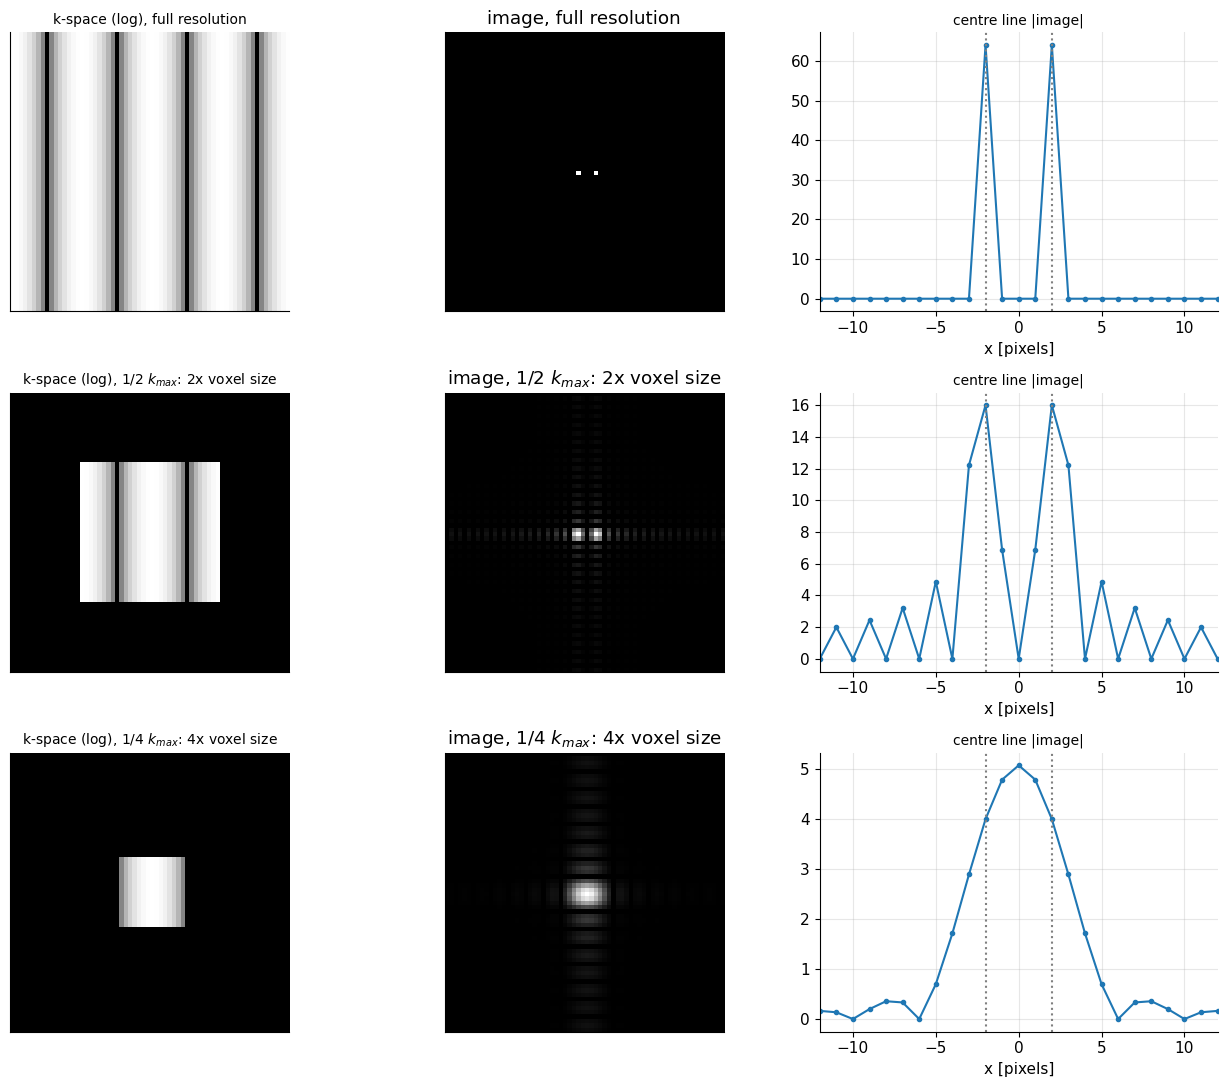

In [7]:
N = 64
kx = np.arange(-N // 2, N // 2) / N                     # cycles per pixel
# Two points at x = -2 and x = +2 pixels on the centre row (y = 0): M = exp(-i2pi k(-2)) + exp(-i2pi k(+2))
kdata = np.outer(np.ones(N), np.exp(1j * np.pi * kx * 4) + np.exp(-1j * np.pi * kx * 4))

def truncate(K, frac):
    """Keep only |k| < frac * k_max in both directions (zero the rest)."""
    n = K.shape[0]; keep = int(round(frac * n / 2))
    out = np.zeros_like(K)
    out[n // 2 - keep:n // 2 + keep, n // 2 - keep:n // 2 + keep] = K[n // 2 - keep:n // 2 + keep, n // 2 - keep:n // 2 + keep]
    return out

fig, axs = plt.subplots(3, 3, figsize=(13, 11))
for r, (frac, t) in enumerate([(1, 'full resolution'), (0.5, r'1/2 $k_{max}$: 2x voxel size'), (0.25, r'1/4 $k_{max}$: 4x voxel size')]):
    kd = truncate(kdata, frac)
    rec = mt.ifft2c(kd)
    axs[r, 0].imshow(np.log10(np.abs(kd) + 1e-1), cmap='gray'); axs[r, 0].set_title('k-space (log), ' + t, fontsize=10)
    mt.show_image(rec, ax=axs[r, 1], title='image, ' + t)
    xs = np.arange(N) - N // 2
    axs[r, 2].plot(xs, np.abs(rec[N // 2, :]), 'o-', ms=3); axs[r, 2].set_xlim(-12, 12)
    axs[r, 2].axvline(-2, color='gray', ls=':'); axs[r, 2].axvline(2, color='gray', ls=':')
    axs[r, 2].set_title('centre line |image|', fontsize=10); axs[r, 2].set_xlabel('x [pixels]')
    axs[r, 0].set_xticks([]); axs[r, 0].set_yticks([]); axs[r, 0].grid(False)
plt.tight_layout(); plt.show()

At full resolution the two points are crisp; at $k_{max}/2$ each is a 2-pixel-wide sinc blob but the two are still separated; at $k_{max}/4$ the blobs (≈4.8 pixels FWHM) merge — the 4-pixel separation is no longer resolved.

### 3.2 The point spread function (PSF)

The image of a single point is the **point spread function**; for plain Cartesian sampling it is the Dirichlet kernel ≈ $W_k\,\mathrm{sinc}(W_kx)$. Its main lobe has zeros at $\pm\delta$ and a **full width at half maximum** of $\approx1.21\,\delta$; its side lobes (−22 % for the first one) cause ringing. A detailed treatment, including relaxation during the readout and windowing, is in [Point Spread Function Analysis](I1_Point_Spread_Function_Analysis.ipynb).

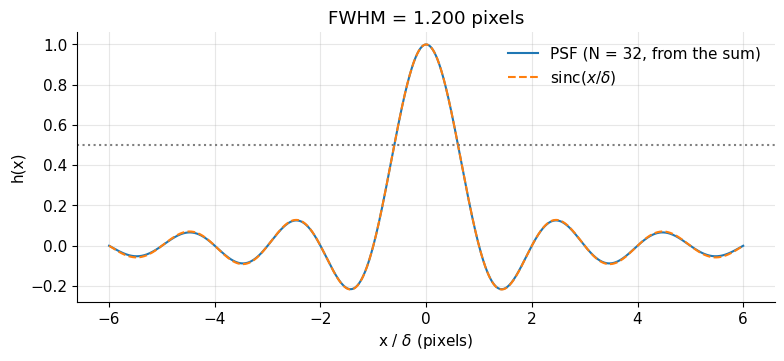

In [8]:
N = 32
FOV = 0.24
delta = FOV / N
xf = np.linspace(-6 * delta, 6 * delta, 2001)
k = np.arange(-N // 2, N // 2) / FOV
h = (np.exp(1j * 2 * np.pi * np.outer(xf, k)).sum(axis=1) / N).real   # Dirichlet kernel, normalized to 1 at 0
half = xf[np.abs(h) >= 0.5]
fwhm = half.max() - half.min()
plt.figure(figsize=(9, 3.5))
plt.plot(xf / delta, h, label='PSF (N = 32, from the sum)')
plt.plot(xf / delta, mt.sinc(xf / delta), '--', label=r'sinc$(x/\delta)$')
plt.axhline(0.5, color='gray', ls=':'); plt.xlabel(r'x / $\delta$ (pixels)'); plt.ylabel('h(x)')
plt.title(f'FWHM = {fwhm/delta:.3f} pixels'); plt.legend(); plt.show()

The PSF has a FWHM of ~1.21 pixels and zero crossings at every integer pixel — so on the pixel grid a point looks like a single pixel, but between grid points (or for edges) the ripples show.

### 3.3 Truncation: blurring and Gibbs ringing

Limiting $k_{max}$ (multiplying k-space by a rect) convolves the image with the sinc PSF: edges get blurred over $\sim\delta$ and show **Gibbs ringing** — oscillations next to sharp edges whose overshoot stays ≈ 9 % of the jump no matter how many samples are taken (only the ripples get narrower). We use an analytic disk phantom, keep only the central $n$ samples, and zero-fill to 256 so that all images are displayed on the same fine grid.

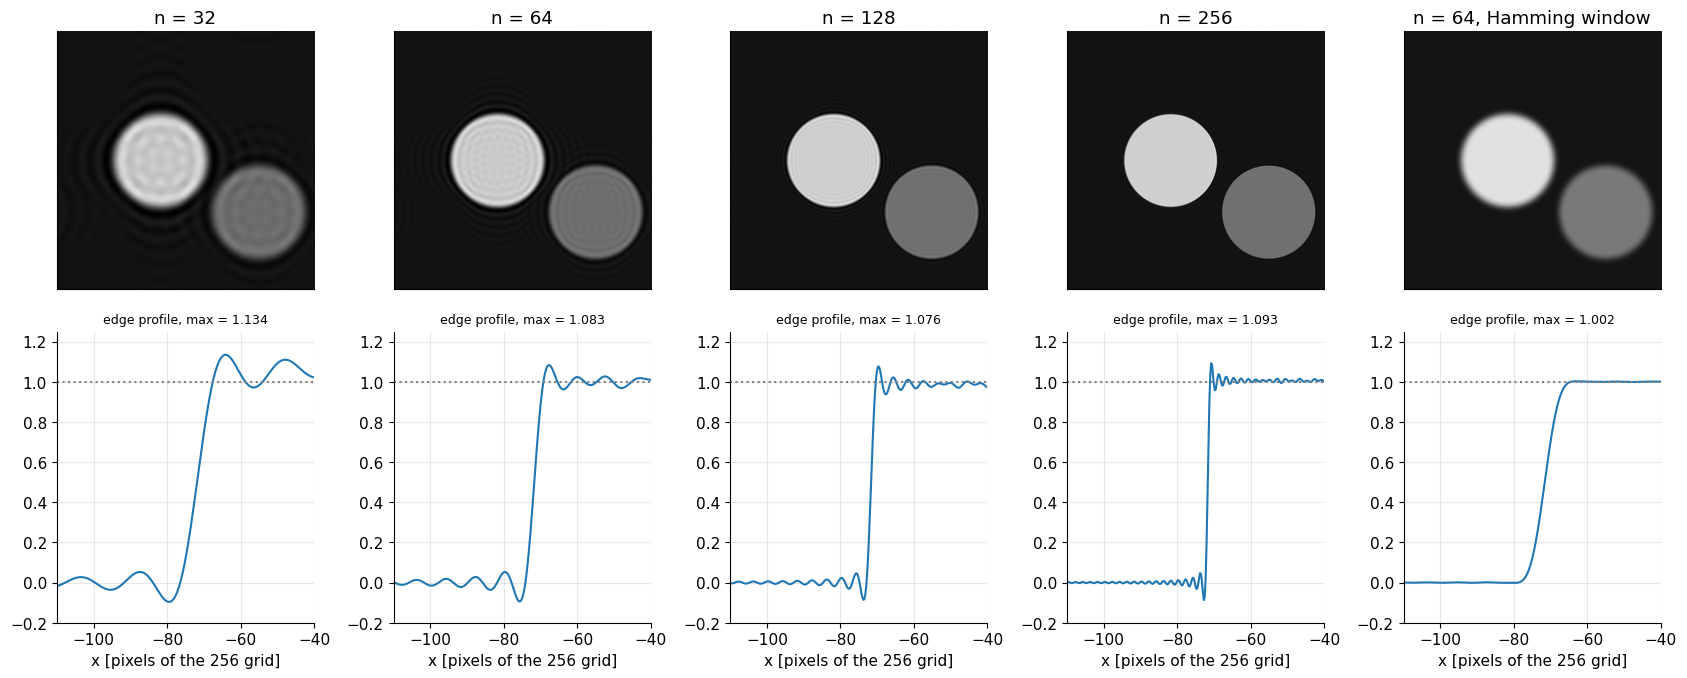

In [9]:
N = 256
Kd = mt.disk_phantom_kspace(N, centers=((-0.1, 0.0), (0.28, 0.2)), radius=0.18, values=(1.0, 0.5))   # edge of disk 1 at x = -72 px

def keep_center(K, n, window=None, pad=1):
    """Keep the central n x n samples of K (optionally windowed) and zero-fill to pad * size(K)."""
    c = K.shape[0] // 2; C = pad * K.shape[0] // 2
    out = np.zeros((pad * K.shape[0],) * 2, complex)
    out[C - n // 2:C + n // 2, C - n // 2:C + n // 2] = K[c - n // 2:c + n // 2, c - n // 2:c + n // 2] * \
        (1 if window is None else np.outer(window(n), window(n)))
    return out

configs = [(32, None, 'n = 32'), (64, None, 'n = 64'), (128, None, 'n = 128'), (256, None, 'n = 256'), (64, np.hamming, 'n = 64, Hamming window')]
fig, axs = plt.subplots(2, 5, figsize=(17, 7))
for c, (n, win, t) in enumerate(configs):
    img = mt.ifft2c(keep_center(Kd, n, win)).real
    mt.show_image(img, ax=axs[0, c], vmin=-0.1, vmax=1.15 * np.abs(img).max(), title=t)
    fine = mt.ifft2c(keep_center(Kd, n, win, pad=4)).real     # 4x zero-filled: resolves the ripple peaks
    xs = (np.arange(4 * N) - 2 * N) / 4                        # position in pixels of the 256 grid
    prof = fine[2 * N, :] / fine[2 * N, 2 * N - 4 * 26]        # centre row, normalized by the plateau inside disk 1
    sel = (xs > -110) & (xs < -40)
    axs[1, c].plot(xs, prof); axs[1, c].set_xlim(-110, -40)
    axs[1, c].axhline(1.0, color='gray', ls=':'); axs[1, c].set_ylim(-0.2, 1.25)
    axs[1, c].set_title(f'edge profile, max = {prof[sel].max():.3f}', fontsize=9)
    axs[1, c].set_xlabel('x [pixels of the 256 grid]')
plt.tight_layout(); plt.show()

Fewer samples → wider blur and wider ripples; but the overshoot next to the edge does **not** shrink with more samples — it stays at roughly 8–9 % (the 1D theory value is ≈ 9 %; for $n=32$ the plateau itself still ripples, so the number is larger). That is the Gibbs phenomenon. The profiles were computed on a 4× zero-filled grid so that the narrow ripple peaks are resolved. A smooth window (Hamming) removes the ringing at the cost of extra blurring — a trade-off every reconstruction pipeline makes ([Point Spread Function Analysis](I1_Point_Spread_Function_Analysis.ipynb), ringing as an artifact in [Artifacts](I2_Artifacts.ipynb)).

> **⚠️ Common confusion:** Zero-filling to a bigger matrix (the 256 display grid above) makes smaller pixels but **not** better resolution — the resolution is set by $k_{max}$ of the *acquired* data. Scanner "interpolation" options do exactly this: nicer-looking images, same information.

## 4. From sampling rules to gradients, dwell time and bandwidth

The pulse sequence diagram below (from the original book) shows the Cartesian gradient-echo sequence with all relevant parameters. Its labels map to our symbols as $G_{xr}=G_{x,r}$, $G_{yp}=G_{y,PE}$, $\Delta T_s=\Delta t$ and $RBW=BW_{read}$.

![Cartesian 2D FT pulse sequence with parameters](../images/pulse_sequence-diagram-Cartesian-parameters.png)

### 4.1 Readout (frequency-encode) direction

During the readout the gradient $G_{x,r}$ is constant and the ADC samples every $\Delta t$. The prephasing lobe brings the k-space position to $-k_{x,max}$ first, so at the echo time $TE$ we pass $k_x=0$ ([K-space](F2_K-space.ipynb)):

$$ k_x(t)=\bar\gamma\,G_{x,r}\,(t-TE) \quad\Rightarrow\quad \Delta k_x=\bar\gamma\,G_{x,r}\,\Delta t $$

In words: during one dwell time the k-space position advances by the gradient area of one dwell period times $\bar\gamma$.

where $t$ = time [s], $TE$ = echo time [s], $G_{x,r}$ [T/m], $\Delta t$ [s], $\bar\gamma$ [Hz/T]. Then

$$ FOV_x=\frac{1}{\bar\gamma G_{x,r}\Delta t}=\frac{BW_{read}}{\bar\gamma\,G_{x,r}}, \qquad \delta_x=\frac{1}{N_{read}\Delta k_x}=\frac{1}{\bar\gamma\,G_{x,r}\,T_{read}} $$

In words: the readout FOV is the distance over which the gradient spreads the precession frequencies across exactly the receiver bandwidth; the resolution is set by the total gradient area during the readout, $G_{x,r}T_{read}$.

where $BW_{read}=1/\Delta t$ (total, i.e. from $-BW_{read}/2$ to $+BW_{read}/2$), $T_{read}=N_{read}\Delta t$.

> **🧭 Intuition (frequency view of the same rule):** With the gradient on, a spin at $x$ precesses at $f=\bar\gamma G_{x,r}x$ (after demodulation). The ADC samples a *complex* signal at rate $1/\Delta t$, so by Nyquist it can unambiguously represent frequencies in $[-\tfrac{1}{2\Delta t},\tfrac{1}{2\Delta t})$ — a band of width $BW_{read}$. Positions whose frequency falls outside that band are mistaken for in-band frequencies: wrap-around. Setting $\bar\gamma G_{x,r}FOV_x=BW_{read}$ is the same statement as $FOV=1/\Delta k$.

Two useful by-products:

* **Bandwidth per pixel:** $BW_{pixel}=BW_{read}/N_{read}=\bar\gamma G_{x,r}\delta_x=1/T_{read}$ — the frequency difference between neighbouring pixels.
* **Chemical-shift displacement:** fat precesses $\Delta f_{cs}\approx-447$ Hz slower than water at 3 T, so the gradient maps it to a shifted position: displacement $=\Delta f_{cs}/BW_{pixel}$ pixels ([Artifacts](I2_Artifacts.ipynb)).

### 4.2 Phase-encode direction

Each phase-encode step $n=1,\dots,N_{PE}$ applies a lobe of amplitude $G_y^{(n)}$ for $t_y$ before the readout ([Spatial Encoding](F1_Spatial_Encoding.ipynb)), placing the line at $k_y^{(n)}=\bar\gamma G_y^{(n)}t_y$. With amplitude increment $G_{yi}$:

$$ \Delta k_y=\bar\gamma\,G_{yi}\,t_y\quad\Rightarrow\quad FOV_y=\frac{1}{\bar\gamma\,G_{yi}\,t_y} $$

In words: the FOV in $y$ is set by the *difference* of gradient area between neighbouring phase-encode steps.

$$ k_{y,max}=\bar\gamma\,G_{y,PE}\,t_y\quad\Rightarrow\quad \delta_y=\frac{1}{2k_{y,max}}=\frac{1}{2\,\bar\gamma\,G_{y,PE}\,t_y} $$

In words: the resolution in $y$ is set by the *largest* phase-encode gradient area.

where $G_{yi}$ [T/m] = increment, $t_y$ [s] = lobe duration, $G_{y,PE}$ [T/m] = largest amplitude. (The original's Cartesian chapter wrote $FOV_y=1/(\bar\gamma G_{yi}\Delta t_y)$; the correct duration is the lobe duration $t_y$ — the *area increment* $G_{yi}t_y$ is what matters. For trapezoidal lobes replace $G\,t_y$ by the lobe area.)

> **📐 Math note (the off-by-one):** With the symmetric scheme $G_y^{(n)}=-G_{y,PE}+(n-1)G_{yi}$ (as in the original), $2G_{y,PE}=(N_{PE}-1)G_{yi}$, so $2k_{y,max}=(N_{PE}-1)\Delta k_y$ and $\delta_y=FOV_y/(N_{PE}-1)$; for even $N_{PE}$ this grid also *misses* $k_y=0$. Scanners therefore use $k_y=(n-1-N_{PE}/2)\Delta k_y$, i.e. from $-N_{PE}/2$ to $N_{PE}/2-1$ steps: $k=0$ is sampled, $W_k=N_{PE}\Delta k_y$ exactly, and $\delta_y=FOV_y/N_{PE}$. For $N_{PE}\ge128$ the difference is below 1 %.

In the slice direction, the resolution is the slice thickness $\delta_z=\Delta z=BW_{rf}/(\bar\gamma G_{z,SS})$ ([Slice Selection](E2_Slice_Selection.ipynb)); for 3D imaging $z$ is phase-encoded like $y$ ([Volumetric Imaging](H1_Volumetric_Imaging.ipynb)).

### 4.3 Worked design example

**Goal:** 3 T, $FOV_x=FOV_y=240$ mm, matrix $256\times256$, receiver bandwidth $BW_{read}=64$ kHz (often displayed as "±32 kHz" or "250 Hz/pixel"), phase-encode lobe $t_y=1$ ms. Compute everything by hand first:

| Quantity | Formula | Value |
|---|---|---|
| $\Delta k$ | $1/FOV$ | $1/0.24 = 4.17\ \mathrm{m^{-1}}$ |
| $k_{max}$ | $N\Delta k/2$ | $533\ \mathrm{m^{-1}}$ |
| $\delta$ | $FOV/N=1/(2k_{max})$ | 0.94 mm |
| $\Delta t$ | $1/BW_{read}$ | 15.6 µs |
| $T_{read}$ | $N_{read}\Delta t$ | 4.0 ms |
| $BW_{pixel}$ | $BW_{read}/N_{read}$ | 250 Hz |
| $G_{x,r}$ | $BW_{read}/(\bar\gamma FOV_x)$ | $64\,000/(42.58\times10^6\cdot0.24)=6.26$ mT/m |
| $G_{yi}$ | $\Delta k_y/(\bar\gamma t_y)$ | 0.098 mT/m |
| largest $\lvert G_y\rvert$ | $(N_{PE}/2)G_{yi}$ | 12.5 mT/m |

Then the same in code — a small reusable function:

In [10]:
def cartesian_design(FOV_x, FOV_y, N_read, N_pe, BW_read, t_y, B0=3.0, G_max=40e-3, gamma_bar=mt.GAMMA_BAR):
    """Gradient/ADC parameters for a 2D Cartesian readout. All SI units (m, Hz, s, T/m).
    Uses the asymmetric k_y grid -N/2..N/2-1 (largest |k_y| = N_pe/2 * Delta k_y)."""
    d = {}
    d['dk_x [1/m]'] = 1 / FOV_x
    d['dk_y [1/m]'] = 1 / FOV_y
    d['k_x,max [1/m]'] = N_read / (2 * FOV_x)
    d['k_y,max [1/m]'] = N_pe / (2 * FOV_y)
    d['delta_x [mm]'] = FOV_x / N_read * 1e3
    d['delta_y [mm]'] = FOV_y / N_pe * 1e3
    dt = 1 / BW_read
    d['dwell time [us]'] = dt * 1e6
    d['T_read [ms]'] = N_read * dt * 1e3
    d['BW/pixel [Hz]'] = BW_read / N_read
    Gx = BW_read / (gamma_bar * FOV_x)
    d['G_x,r [mT/m]'] = Gx * 1e3
    Gyi = (1 / FOV_y) / (gamma_bar * t_y)
    d['G_yi [mT/m]'] = Gyi * 1e3
    d['max |G_y| [mT/m]'] = N_pe / 2 * Gyi * 1e3
    d['readout prephaser in t_y [mT/m]'] = Gx * N_read * dt / 2 / t_y * 1e3   # half the readout area in t_y
    d['fat shift [pixels]'] = abs(mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)) / (BW_read / N_read)
    d['within G_max?'] = max(Gx, N_pe / 2 * Gyi, d['readout prephaser in t_y [mT/m]'] * 1e-3) <= G_max
    return d

design = cartesian_design(FOV_x=0.24, FOV_y=0.24, N_read=256, N_pe=256, BW_read=64e3, t_y=1e-3)
for key, val in design.items():
    print(f"{key:34s} {val:.4g}" if not isinstance(val, (bool, np.bool_)) else f"{key:34s} {val}")

dk_x [1/m]                         4.167
dk_y [1/m]                         4.167
k_x,max [1/m]                      533.3
k_y,max [1/m]                      533.3
delta_x [mm]                       0.9375
delta_y [mm]                       0.9375
dwell time [us]                    15.62
T_read [ms]                        4
BW/pixel [Hz]                      250
G_x,r [mT/m]                       6.263
G_yi [mT/m]                        0.09786
max |G_y| [mT/m]                   12.53
readout prephaser in t_y [mT/m]    12.53
fat shift [pixels]                 1.788
within G_max?                      True


All gradient amplitudes are well below a typical $G_{max}=40$ mT/m; fat is displaced by 1.8 pixels (≈ 1.7 mm). Now explore how the readout parameters depend on the bandwidth for this FOV and matrix:

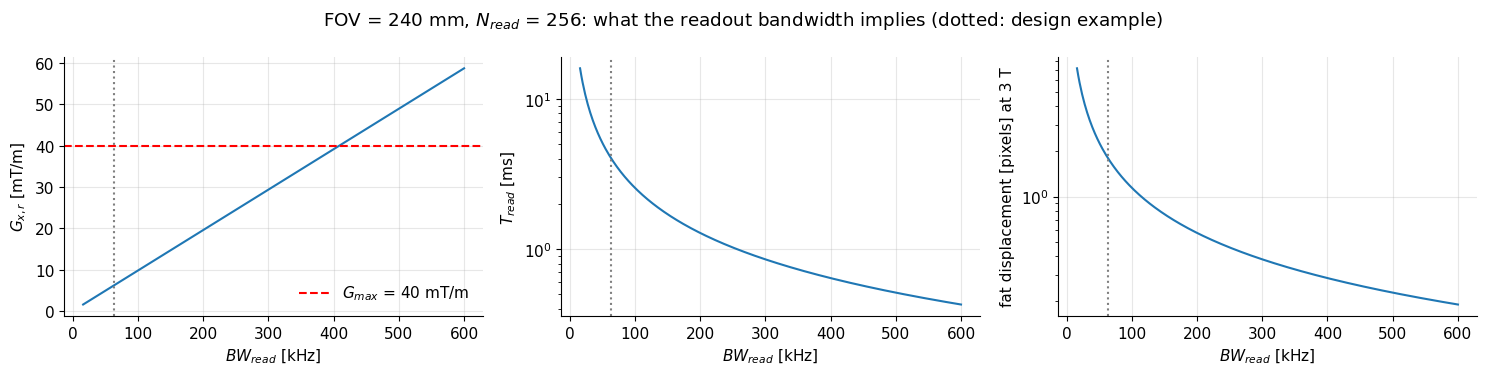

In [11]:
BW = np.linspace(16e3, 600e3, 300)                     # total readout bandwidth [Hz]
FOVx, Nr, Gmax = 0.24, 256, 40e-3
Gx = BW / (mt.GAMMA_BAR * FOVx)                         # [T/m]
Tread = Nr / BW                                         # [s]
fat_px = abs(mt.ppm_to_hz(mt.FAT_SHIFT_PPM, 3.0)) / (BW / Nr)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].plot(BW / 1e3, Gx * 1e3); axs[0].axhline(Gmax * 1e3, color='r', ls='--', label='$G_{max}$ = 40 mT/m')
axs[0].set_ylabel('$G_{x,r}$ [mT/m]'); axs[0].legend()
axs[1].plot(BW / 1e3, Tread * 1e3); axs[1].set_ylabel('$T_{read}$ [ms]'); axs[1].set_yscale('log')
axs[2].plot(BW / 1e3, fat_px); axs[2].set_ylabel('fat displacement [pixels] at 3 T'); axs[2].set_yscale('log')
for a in axs:
    a.set_xlabel('$BW_{read}$ [kHz]'); a.axvline(64, color='gray', ls=':')
plt.suptitle('FOV = 240 mm, $N_{read}$ = 256: what the readout bandwidth implies (dotted: design example)')
plt.tight_layout(); plt.show()

High bandwidth → strong gradient, short readout (shorter TE/TR possible, less fat shift, less $T_2^*$ blurring) but **lower SNR**, because SNR ∝ $\sqrt{T_{read}}$ ([Signal to Noise Ratio](G2_Signal_to_Noise_Ratio.ipynb)). Low bandwidth → weak gradient, long readout, more SNR but larger fat shift and distortion. The FOV and resolution themselves do not depend on the bandwidth once $G_{x,r}$ is matched to it.

> **🔧 Engineering reality:** What limits resolution in hardware? From $\delta_x=1/(\bar\gamma G_{x,r}T_{read})$: the gradient amplitude ($G_{max}$ ≈ 40–80 mT/m on clinical systems, limited by amplifier current and coil heating), and the readout duration (limited by $T_2^*$ decay, which blurs the image, and by TR/TE). With 40 mT/m and $T_{read}=4$ ms, $\delta_x$ could be as small as $1/(42.58\times10^6\cdot0.04\cdot0.004)=0.15$ mm — but such small voxels contain so few spins that SNR, not gradients, is usually the true limit. Real gradients are trapezoids with finite **slew rate**; samples are often also taken on the ramps ("ramp sampling") and regridded. See [Gradient System Engineering](B4_Gradient_System_Engineering.ipynb).

## 5. Readout oversampling: why it is free, and why it is needed

In the readout direction we can double $FOV_x$ by sampling twice as fast ($\Delta t\to\Delta t/2$, $N_{read}\to2N_{read}$) at the **same gradient** $G_{x,r}$ and **same** $T_{read}$: $k_{x,max}$ is unchanged (same resolution), $\Delta k_x$ halves (double FOV). The readout takes exactly as long, so the **scan time does not change**. The extra image region is cropped away after reconstruction ([Image Reconstruction](F3_Image_Reconstruction.ipynb)). SNR is also unchanged after cropping: we take twice as many samples, but each covers twice the noise bandwidth, so the total measurement time $T_{meas}$ that sets SNR is the same.

Doubling $FOV_y$, by contrast, requires halving $\Delta k_y$ at the same $k_{y,max}$, i.e. **twice as many phase-encode steps = twice as many TRs = twice the scan time**.

Why bother? The receiver contains an **anti-aliasing filter** that suppresses frequencies outside the band; without it, any signal from outside $FOV_x$ would wrap in. But no filter is perfectly sharp: its response $|H(f)|$ rolls off near the band edge. Without oversampling, the roll-off darkens the image edges *and* lets some outside signal through (to alias). With 2× oversampling the flat part of the filter covers the displayed FOV and the roll-off, plus whatever aliases, falls into the discarded region.

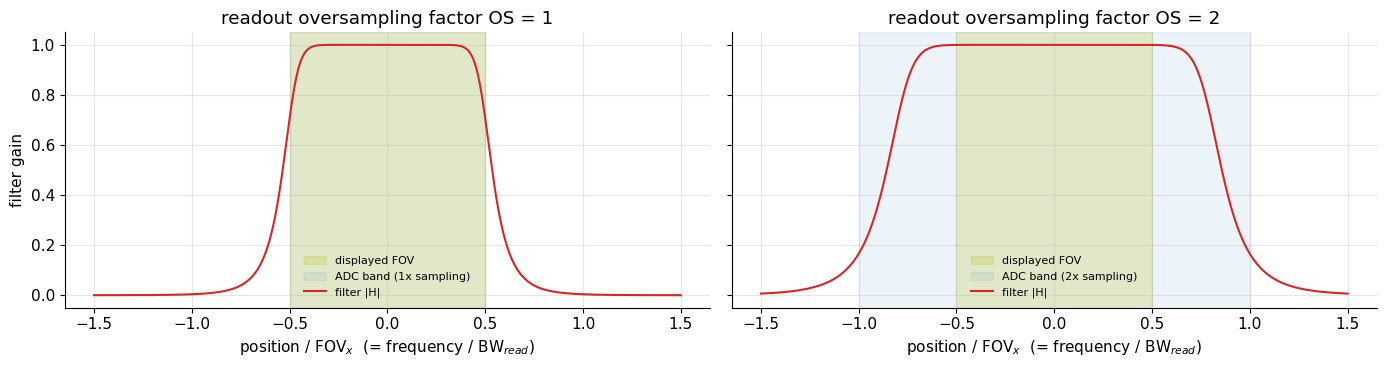

In [12]:
def butterworth(f, fc, order=8):
    """Magnitude response of an order-n Butterworth low-pass filter (a typical anti-aliasing filter model)."""
    return 1 / np.sqrt(1 + (np.abs(f) / fc) ** (2 * order))

xr = np.linspace(-1.5, 1.5, 1001)                   # position in units of the displayed FOV_x (frequency = position)
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, OS in zip(axs, [1, 2]):
    nyq = OS / 2                                    # ADC band edge in units of FOV_x
    fc = 0.5 if OS == 1 else 0.8                    # cutoff must lie within the ADC band
    ax.axvspan(-0.5, 0.5, color='y', alpha=0.2, label='displayed FOV')
    ax.axvspan(-nyq, nyq, color='C0', alpha=0.08, label=f'ADC band ({OS}x sampling)')
    ax.plot(xr, butterworth(xr, fc), 'C3', label='filter |H|')
    ax.set_xlabel('position / FOV$_x$  (= frequency / BW$_{read}$)'); ax.set_title(f'readout oversampling factor OS = {OS}')
    ax.legend(fontsize=8, loc='lower center')
axs[0].set_ylabel('filter gain')
plt.tight_layout(); plt.show()

Left: without oversampling the filter must already cut at the FOV edge, so edge pixels are attenuated (to 0.7 at the very edge) and signal from just outside still passes and wraps. Right: with 2× oversampling the gain is flat across the displayed FOV.

The knee raw data provided with this course were acquired with 2× readout oversampling (640 samples for a 320 matrix). Cropping (correct) versus throwing away every second readout sample (what you would get by sampling at $2\Delta t$ *without* any anti-aliasing filter):

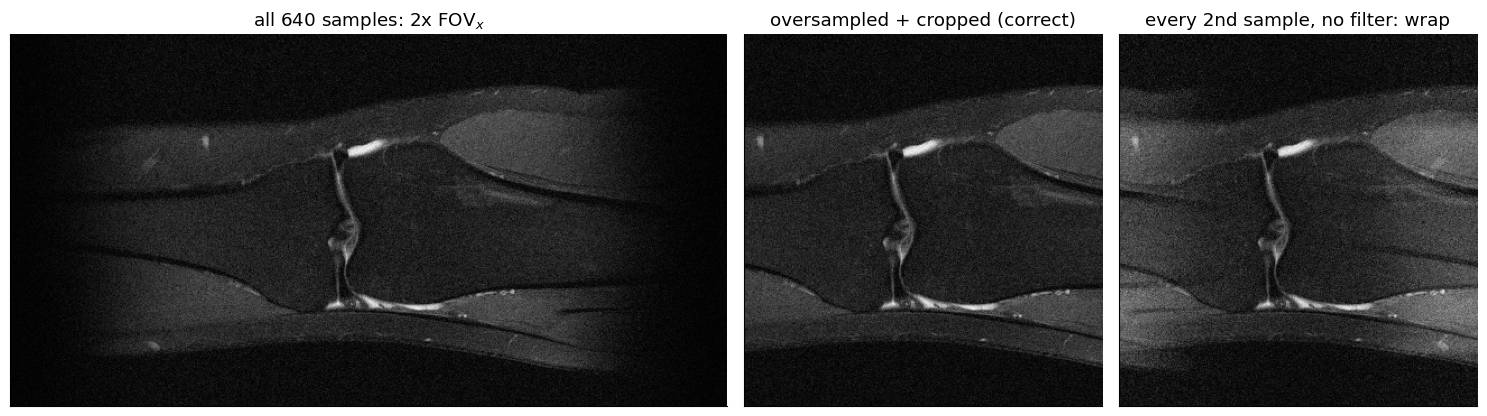

In [13]:
kknee = loadmat('../data/coronal_fatsat_2D_knee.mat')['kdata']        # 332 PE lines x 640 readout samples
hyb = mt.ifftc(kknee, axis=1)                                          # readout direction -> x
cropped = mt.ifftc(hyb[:, 160:480], axis=0)                            # keep central half: proper recon
decimated = mt.ifft2c(kknee[:, ::2])                                    # 320 samples at 2x dwell: FOV_x halved, no filter
full = mt.ifft2c(kknee)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={'width_ratios': [2, 1, 1]})
mt.show_image(full, ax=axs[0], title='all 640 samples: 2x FOV$_x$')
mt.show_image(cropped, ax=axs[1], title='oversampled + cropped (correct)')
mt.show_image(decimated, ax=axs[2], title='every 2nd sample, no filter: wrap')
plt.tight_layout(); plt.show()

In the decimated image the thigh and calf, which lie outside the 320-pixel FOV, fold back over the knee from the opposite sides (left and right edges look "doubled"); the cropped image is clean. On a real scanner the anti-aliasing filter would suppress most of that, leaving darkened edges instead.

> **🔧 Engineering reality:** Modern receivers digitize at a high fixed rate (tens of MHz, often directly at RF) and reduce the rate digitally ("decimation") with very sharp digital filters ([RF System and Receive Chain](B5_RF_System_and_Receive_Chain.ipynb)). Readout wrap-around is therefore rare; 2× oversampling is nevertheless a default on most systems because it costs only data volume and reconstruction time, not scan time.

### Try it yourself

Change the number of k-space samples $N$ and the undersampling factor (which multiplies $\Delta k$) in the 1D rect-object experiment. (Requires `ipywidgets`; the static figures above show the default cases.)

In [14]:
try:
    from ipywidgets import interact, IntSlider
    def explore(N=64, R=1, width_cm=16):
        parts = [(width_cm / 100, 0.0, 1.0), (0.03, 0.04, 0.6)]
        FOV_eff = 0.24 / R                       # Delta k multiplied by R -> FOV divided by R
        mhat, k, M = recon_1d(parts, FOV_eff, N, x)
        plt.figure(figsize=(11, 3.5))
        plt.axvspan(-FOV_eff / 2 * 1e3, FOV_eff / 2 * 1e3, color='y', alpha=0.15)
        plt.plot(x * 1e3, rect_object(x, parts), 'k--', lw=1); plt.plot(x * 1e3, mhat.real, 'C3')
        plt.title(f'FOV = {FOV_eff*1e3:.0f} mm, delta = {FOV_eff/N*1e3:.1f} mm'); plt.xlabel('x [mm]'); plt.show()
    interact(explore, N=IntSlider(value=64, min=8, max=256, step=8), R=IntSlider(value=1, min=1, max=4),
             width_cm=IntSlider(value=16, min=4, max=40, step=2))
except ImportError:
    print("ipywidgets not available - use the static figures above.")

interactive(children=(IntSlider(value=64, description='N', max=256, min=8, step=8), IntSlider(value=1, descrip…

## Key takeaways

* **$FOV=1/\Delta k$** — sampling k-space on a grid of spacing $\Delta k$ makes the image periodic with period $1/\Delta k$ (comb ↔ comb). Objects larger than the FOV wrap around (aliasing).
* **$\delta=1/(2k_{max})=FOV/N$** — measuring only $|k|\le k_{max}$ convolves the image with a sinc PSF (rect ↔ sinc): blur of ~1 pixel (FWHM ≈ 1.21 δ) and Gibbs ringing (~9 % overshoot) at edges.
* Readout: $FOV_x=BW_{read}/(\bar\gamma G_{x,r})$, $\delta_x=1/(\bar\gamma G_{x,r}T_{read})$, $BW_{pixel}=1/T_{read}$. Phase encode: $FOV_y=1/(\bar\gamma G_{yi}t_y)$, $\delta_y=1/(2\bar\gamma G_{y,PE}t_y)$.
* For a fixed FOV and matrix, the readout bandwidth sets $G_{x,r}$ and $T_{read}$: high BW = short readout, less fat shift, lower SNR.
* Readout oversampling doubles $FOV_x$ for free (same scan time, same resolution); phase-direction oversampling costs scan time proportionally.
* Zero-filling makes smaller pixels, not better resolution.

## Check your understanding

1. You want $FOV_y=200$ mm with a phase-encode lobe of $t_y=0.8$ ms. What gradient increment $G_{yi}$ is needed?

<details><summary>Answer</summary>

$\Delta k_y=1/0.2=5\ \mathrm{m^{-1}}$, $G_{yi}=\Delta k_y/(\bar\gamma t_y)=5/(42.58\times10^6\cdot0.8\times10^{-3})=1.47\times10^{-4}$ T/m $=0.147$ mT/m.

</details>

2. A colleague halves the number of phase-encode steps "to halve the scan time" and keeps $G_{yi}$ unchanged. What happens to FOV and resolution? What if instead $G_{yi}$ is doubled and $G_{y,PE}$ kept?

<details><summary>Answer</summary>

Keeping $G_{yi}$ (same $\Delta k_y$) and halving $N_{PE}$ halves $k_{y,max}$: same FOV, pixel size in $y$ doubles (coarser resolution). Doubling $G_{yi}$ while keeping $G_{y,PE}$ (same $k_{y,max}$) doubles $\Delta k_y$: same resolution, FOV halved → wrap-around if the object is larger than the new FOV.

</details>

3. With $FOV_x=300$ mm, $N_{read}=320$ and $BW_{read}=100$ kHz at 1.5 T: compute $\Delta t$, $T_{read}$, $G_{x,r}$, $BW_{pixel}$ and the fat shift in pixels (fat ≈ −3.5 ppm).

<details><summary>Answer</summary>

$\Delta t=10$ µs, $T_{read}=3.2$ ms, $G_{x,r}=10^5/(42.58\times10^6\cdot0.3)=7.83$ mT/m, $BW_{pixel}=312.5$ Hz. Fat at 1.5 T: $3.5\times10^{-6}\cdot63.9$ MHz ≈ 224 Hz → 0.72 pixels.

</details>

4. Why does a scanner happily acquire 2× oversampled readouts by default but asks you to accept a longer scan for "phase oversampling"?

<details><summary>Answer</summary>

Readout samples are all taken within the same readout window: doubling the sampling rate doubles $FOV_x$ without lengthening $T_{read}$ or the number of TRs. Each phase-encode line needs its own TR, so doubling $FOV_y$ at the same resolution doubles the number of TRs and the scan time.

</details>

5. After reconstructing with zero-filling from 128 to 512 samples, a vendor advertises "4× higher resolution". Correct?

<details><summary>Answer</summary>

No. Resolution is set by the acquired $k_{max}$, which zero-filling does not change; it only interpolates (sinc interpolation) onto a finer pixel grid. Edges look smoother but details smaller than the original $\delta$ remain unresolved.

</details>

6. In the Gibbs demo, the ringing near the edge got narrower but not smaller with more samples. Why, and how can you reduce it?

<details><summary>Answer</summary>

The overshoot of a truncated Fourier series at a jump converges to ≈ 9 % of the jump independently of $N$ (Gibbs phenomenon); more samples only compress the ripples towards the edge. It can be reduced by windowing k-space smoothly (e.g. Hamming, Hann), at the price of a wider PSF, or by acquiring larger $k_{max}$ so the ripples become sub-pixel.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "FOV and Resolution". Changes: added derivation from comb↔comb and rect↔sinc with continuous-object and stripe-pattern demos, aliasing on analytic and real data, PSF, Gibbs ringing and windowing, hardware relations (gradients, dwell time, bandwidth, off-by-one in phase encoding), a worked design calculator, and readout-oversampling discussion with the knee data. Corrected the original code's unnormalized sinc (the "square" was ~N/π instead of N pixels wide) and the claim that the two test points were 1 pixel apart (they are 4 pixels apart); $FOV_y$ uses the lobe duration $t_y$ (not $\Delta t_y$).*